# World Happiness Report: Exploratory Data Analysis & Insights

- **Author:** Shivshankar Dhareppa Mali
- **Dataset:** World Happiness Report (2015–2019, Kaggle / UN SDSN)
- **Objective:** Exploratory analysis examining socio-economic determinants of subjective well-being across 150+ countries.


### 1. Core library imports

In [1]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')


### 2. Plot configuration and styling

In [2]:
# Clean, minimal plot style without decorative clutter
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.autolayout': True,
    'font.size': 10.5,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10.5,
    'axes.labelweight': 'bold',
    'legend.frameon': True
})


### 3. Data path setup

In [3]:
import urllib.request
from pathlib import Path

data_dir = Path("data") if Path("data").exists() else Path("project-01-world-happiness-eda/data")

# Auto-download datasets if running in Google Colab
if not (data_dir / "2019.csv").exists():
    data_dir = Path("data")
    data_dir.mkdir(parents=True, exist_ok=True)
    base_url = "https://raw.githubusercontent.com/shiv123-coder/HappyEDA/main/data"
    for y in range(2015, 2020):
        fpath = data_dir / f"{y}.csv"
        if not fpath.exists():
            urllib.request.urlretrieve(f"{base_url}/{y}.csv", fpath)

print("Data directory ready:", data_dir.resolve())


Data directory ready: /content/data


### 4. Raw file verification

In [4]:
csv_files = sorted(list(data_dir.glob("*.csv")))
for f in csv_files:
    raw = pd.read_csv(f)
    print(f"{f.name:10s} | Rows: {raw.shape[0]} | Columns: {raw.shape[1]}")


2015.csv   | Rows: 158 | Columns: 12
2016.csv   | Rows: 157 | Columns: 13
2017.csv   | Rows: 155 | Columns: 12
2018.csv   | Rows: 156 | Columns: 9
2019.csv   | Rows: 156 | Columns: 9


### 5. Load latest survey data (2019)

In [5]:
df_2019_raw = pd.read_csv(data_dir / "2019.csv")
df_2019_raw.head()


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


### 6. Schema and column data types

In [6]:
print("Dataset shape:", df_2019_raw.shape)
df_2019_raw.info()


Dataset shape: (156, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


### 7. Missing values audit

In [7]:
df_2019_raw.isna().sum()


,0
Overall rank,0
Country or region,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


### 8. Duplicate records check

In [8]:
dup_count = df_2019_raw.duplicated(subset=['Country or region']).sum()
print(f"Duplicate country entries: {dup_count}")


Duplicate country entries: 0


### Step 1: Summary of dataset inspection
1. The World Happiness Report records national average life evaluations on a 0-to-10 Cantril ladder scale across more than 150 nations.
2. The core explanatory columns quantify economic output (GDP per capita), social support networks, healthy life expectancy, personal freedom, generosity, and corruption perceptions.
3. The raw data covers the years 2015 to 2019 with 155 to 158 surveyed countries per annual release.
4. Data quality is consistently high with zero duplicate countries per release and only a single missing value across all five years (UAE corruption in 2018).
5. Column names and regional groupings differ across release years, requiring schema normalization and a unified region lookup.


## Step 2: Data cleaning and standardization

### Cleaning decisions:
1. **Schema normalization**: Mapped inconsistent yearly column names (such as `Family` vs `Social support`, `Economy (GDP per Capita)` vs `GDP per capita`) to a standard format: `country`, `region`, `rank`, `score`, `gdp`, `social`, `health`, `freedom`, `generosity`, `corruption`, `year`.
2. **Region assignment**: Reconstructed missing regions for 2018 and 2019 using a lookup table built from 2015-2016 entries, with alias resolution for entity naming changes (e.g. Taiwan, Hong Kong, North Macedonia, Gambia).
3. **Missing value imputation**: Imputed the single missing corruption value for UAE in 2018 using the country's average from surrounding survey years (0.288) rather than dropping the country.
4. **Dropped auxiliary columns**: Removed confidence intervals and residuals (whiskers, standard error, dystopia residual) to retain a consistent feature set across all years.


### 9. Unified loader function across survey years

In [9]:
def load_and_standardize(year):
    fpath = data_dir / f"{year}.csv"
    df = pd.read_csv(fpath)
    if year in (2015, 2016):
        out = pd.DataFrame({
            "country": df["Country"].str.strip(),
            "region": df["Region"].str.strip(),
            "rank": df["Happiness Rank"].astype(int),
            "score": df["Happiness Score"].astype(float),
            "gdp": df["Economy (GDP per Capita)"].astype(float),
            "social": df["Family"].astype(float),
            "health": df["Health (Life Expectancy)"].astype(float),
            "freedom": df["Freedom"].astype(float),
            "generosity": df["Generosity"].astype(float),
            "corruption": df["Trust (Government Corruption)"].astype(float),
        })
    elif year == 2017:
        out = pd.DataFrame({
            "country": df["Country"].str.strip(),
            "region": np.nan,
            "rank": df["Happiness.Rank"].astype(int),
            "score": df["Happiness.Score"].astype(float),
            "gdp": df["Economy..GDP.per.Capita."].astype(float),
            "social": df["Family"].astype(float),
            "health": df["Health..Life.Expectancy."].astype(float),
            "freedom": df["Freedom"].astype(float),
            "generosity": df["Generosity"].astype(float),
            "corruption": df["Trust..Government.Corruption."].astype(float),
        })
    else:  # 2018, 2019
        out = pd.DataFrame({
            "country": df["Country or region"].str.strip(),
            "region": np.nan,
            "rank": df["Overall rank"].astype(int),
            "score": df["Score"].astype(float),
            "gdp": df["GDP per capita"].astype(float),
            "social": df["Social support"].astype(float),
            "health": df["Healthy life expectancy"].astype(float),
            "freedom": df["Freedom to make life choices"].astype(float),
            "generosity": df["Generosity"].astype(float),
            "corruption": pd.to_numeric(df["Perceptions of corruption"], errors='coerce'),
        })
    out["year"] = year
    return out


### 10. Merge all years and resolve regional metadata

In [10]:
raw_frames = [load_and_standardize(y) for y in range(2015, 2020)]

# Build region dictionary from 2015 and 2016
region_map = {}
for sub in raw_frames[:2]:
    for country, reg in zip(sub["country"], sub["region"]):
        if pd.notna(reg):
            region_map.setdefault(country, reg)

aliases = {
    "Taiwan Province of China": "Taiwan",
    "Hong Kong S.A.R., China": "Hong Kong",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "North Macedonia": "Macedonia",
    "Somaliland Region": "Somaliland region",
    "Gambia": "Sub-Saharan Africa",
    "South Sudan": "Sub-Saharan Africa",
}

def resolve_region(row):
    if pd.notna(row["region"]):
        return row["region"]
    c = row["country"]
    if c in region_map:
        return region_map[c]
    if c in aliases:
        return region_map.get(aliases[c], aliases[c])
    return "Other"

all_years_df = pd.concat(raw_frames, ignore_index=True)
all_years_df["region"] = all_years_df.apply(resolve_region, axis=1)

# Impute missing UAE corruption in 2018
uae_mean = all_years_df.loc[all_years_df["country"].str.contains("United Arab Emirates") & (all_years_df["year"] != 2018), "corruption"].mean()
all_years_df["corruption"] = all_years_df["corruption"].fillna(uae_mean)

df_2019 = all_years_df[all_years_df["year"] == 2019].copy().reset_index(drop=True)
print(f"Cleaned 2019 dataset: {df_2019.shape[0]} rows, {df_2019.shape[1]} columns")
print(f"Total nulls in 2019 dataset: {df_2019.isna().sum().sum()}")


Cleaned 2019 dataset: 156 rows, 11 columns
Total nulls in 2019 dataset: 0


### 11. Cleaned 2019 sample records

In [11]:
df_2019.head()


,country,region,rank,score,gdp,social,health,freedom,generosity,corruption,year
0,Finland,Western Europe,1,7.769,1.340,1.587,0.986,0.596,0.153,0.393,2019
1,Denmark,Western Europe,2,7.600,1.383,1.573,0.996,0.592,0.252,0.410,2019
2,Norway,Western Europe,3,7.554,1.488,1.582,1.028,0.603,0.271,0.341,2019
3,Iceland,Western Europe,4,7.494,1.380,1.624,1.026,0.591,0.354,0.118,2019
4,Netherlands,Western Europe,5,7.488,1.396,1.522,0.999,0.557,0.322,0.298,2019


## Step 3: Exploratory data analysis

We answer 5 specific analytical questions using groupby, sorting, describe, and correlation methods.


### Question 1: What are the top 10 and bottom 5 countries in 2019, and how do their metrics compare?

In [12]:
top_10 = df_2019.nsmallest(10, 'rank')[['rank', 'country', 'region', 'score', 'gdp', 'social', 'health', 'freedom']]
top_10


,rank,country,region,score,gdp,social,health,freedom
0,1,Finland,Western Europe,7.769,1.340,1.587,0.986,0.596
1,2,Denmark,Western Europe,7.600,1.383,1.573,0.996,0.592
2,3,Norway,Western Europe,7.554,1.488,1.582,1.028,0.603
3,4,Iceland,Western Europe,7.494,1.380,1.624,1.026,0.591
4,5,Netherlands,Western Europe,7.488,1.396,1.522,0.999,0.557
5,6,Switzerland,Western Europe,7.480,1.452,1.526,1.052,0.572
6,7,Sweden,Western Europe,7.343,1.387,1.487,1.009,0.574
7,8,New Zealand,Australia and New Zealand,7.307,1.303,1.557,1.026,0.585
8,9,Canada,North America,7.278,1.365,1.505,1.039,0.584
9,10,Austria,Western Europe,7.246,1.376,1.475,1.016,0.532


### Bottom 5 least happy countries in 2019

In [13]:
bottom_5 = df_2019.nlargest(5, 'rank')[['rank', 'country', 'region', 'score', 'gdp', 'social', 'health', 'freedom']]
bottom_5


,rank,country,region,score,gdp,social,health,freedom
155,156,South Sudan,Sub-Saharan Africa,2.853,0.306,0.575,0.295,0.010
154,155,Central African Republic,Sub-Saharan Africa,3.083,0.026,0.000,0.105,0.225
153,154,Afghanistan,Southern Asia,3.203,0.350,0.517,0.361,0.000
152,153,Tanzania,Sub-Saharan Africa,3.231,0.476,0.885,0.499,0.417
151,152,Rwanda,Sub-Saharan Africa,3.334,0.359,0.711,0.614,0.555


### Metric comparison: Top 10 vs Bottom 5 means

In [14]:
comp = pd.DataFrame({
    'Dimension': ['Happiness Score', 'GDP per Capita', 'Social Support', 'Healthy Life Expectancy', 'Freedom'],
    'Top 10 Mean': [top_10['score'].mean(), top_10['gdp'].mean(), top_10['social'].mean(), top_10['health'].mean(), top_10['freedom'].mean()],
    'Bottom 5 Mean': [bottom_5['score'].mean(), bottom_5['gdp'].mean(), bottom_5['social'].mean(), bottom_5['health'].mean(), bottom_5['freedom'].mean()]
})
comp['Ratio (Top / Bottom)'] = (comp['Top 10 Mean'] / comp['Bottom 5 Mean']).round(2)
comp.round(3)


,Dimension,Top 10 Mean,Bottom 5 Mean,Ratio (Top / Bottom)
0,Happiness Score,7.456,3.141,2.37
1,GDP per Capita,1.387,0.303,4.57
2,Social Support,1.544,0.538,2.87
3,Healthy Life Expectancy,1.018,0.375,2.72
4,Freedom,0.579,0.241,2.40


### Question 2: Which factors show the strongest linear correlation with Happiness Score?

In [15]:
factors = ['score', 'gdp', 'social', 'health', 'freedom', 'generosity', 'corruption']
corr_series = df_2019[factors].corr()['score'].drop('score').sort_values(ascending=False)

pd.DataFrame({
    'Factor': corr_series.index,
    'Pearson Correlation (r)': corr_series.values.round(3),
    'Strength': ['Strong' if v >= 0.70 else 'Moderate' if v >= 0.50 else 'Weak' for v in corr_series.values]
})


,Factor,Pearson Correlation (r),Strength
0,gdp,0.794,Strong
1,health,0.780,Strong
2,social,0.777,Strong
3,freedom,0.567,Moderate
4,corruption,0.386,Weak
5,generosity,0.076,Weak


### Question 3: How do happiness scores vary across geographic regions, and which region has the largest spread?

In [16]:
reg_stats = df_2019.groupby('region')['score'].agg(
    Count='count', Mean='mean', Median='median', Std='std', Min='min', Max='max'
)
reg_stats['Spread (Max - Min)'] = reg_stats['Max'] - reg_stats['Min']
reg_stats.sort_values(by='Mean', ascending=False).round(3)


,Count,Mean,Median,Std,Min,Max,Spread (Max - Min)
region,,,,,,,
Australia and New Zealand,2,7.268,7.268,0.056,7.228,7.307,0.079
North America,2,7.085,7.085,0.273,6.892,7.278,0.386
Western Europe,21,6.842,7.021,0.711,5.287,7.769,2.482
Latin America and Caribbean,21,5.954,6.105,0.724,3.597,7.167,3.570
Eastern Asia,6,5.689,5.658,0.476,5.191,6.446,1.255
Central and Eastern Europe,29,5.562,5.529,0.583,4.332,6.852,2.520
Southeastern Asia,9,5.274,5.192,0.618,4.360,6.262,1.902
Middle East and Northern Africa,19,5.237,5.208,1.060,3.380,7.139,3.759
Southern Asia,7,4.527,4.456,0.793,3.203,5.653,2.450


### Question 4: How did national happiness change over the 5-year span from 2015 to 2019?

In [17]:
df_15 = all_years_df[all_years_df['year'] == 2015][['country', 'score', 'rank', 'region']].rename(
    columns={'score': 'score_2015', 'rank': 'rank_2015'}
)
df_19_sub = df_2019[['country', 'score', 'rank']].rename(
    columns={'score': 'score_2019', 'rank': 'rank_2019'}
)

trend_df = pd.merge(df_15, df_19_sub, on='country', how='inner')
trend_df['Score Delta'] = (trend_df['score_2019'] - trend_df['score_2015']).round(3)
trend_df['Rank Delta'] = trend_df['rank_2015'] - trend_df['rank_2019']

print("Top 5 Countries with Greatest Score Improvement (2015 to 2019):")
display(trend_df.nlargest(5, 'Score Delta')[['country', 'region', 'score_2015', 'score_2019', 'Score Delta', 'Rank Delta']])

print("\nTop 5 Countries with Steepest Score Decline (2015 to 2019):")
display(trend_df.nsmallest(5, 'Score Delta')[['country', 'region', 'score_2015', 'score_2019', 'Score Delta', 'Rank Delta']])


Top 5 Countries with Greatest Score Improvement (2015 to 2019):


,country,region,score_2015,score_2019,Score Delta,Rank Delta
145,Benin,Sub-Saharan Africa,3.340,4.883,1.543,53
141,Ivory Coast,Sub-Saharan Africa,3.655,4.944,1.289,52
148,Togo,Sub-Saharan Africa,2.839,4.085,1.246,19
98,Honduras,Latin America and Caribbean,4.788,5.860,1.072,46
142,Burkina Faso,Sub-Saharan Africa,3.587,4.587,1.000,37



Top 5 Countries with Steepest Score Decline (2015 to 2019):


,country,region,score_2015,score_2019,Score Delta,Rank Delta
21,Venezuela,Latin America and Caribbean,6.810,4.707,-2.103,-85
90,Lesotho,Sub-Saharan Africa,4.898,3.802,-1.096,-47
80,Zambia,Sub-Saharan Africa,5.129,4.107,-1.022,-53
108,Zimbabwe,Sub-Saharan Africa,4.610,3.663,-0.947,-31
111,Haiti,Latin America and Caribbean,4.518,3.597,-0.921,-28


### Question 5: Which countries overperform or underperform their GDP rank in subjective happiness?

In [18]:
df_2019['gdp_rank'] = df_2019['gdp'].rank(ascending=False, method='min').astype(int)
df_2019['score_rank'] = df_2019['score'].rank(ascending=False, method='min').astype(int)
df_2019['rank_gap'] = df_2019['gdp_rank'] - df_2019['score_rank']

print("Top 5 Countries Punching Above Their Wealth (Happiness Rank >> GDP Rank):")
display(df_2019.nlargest(5, 'rank_gap')[['country', 'region', 'score', 'score_rank', 'gdp', 'gdp_rank', 'rank_gap']])

print("\nTop 5 Countries Underperforming Their Wealth (Happiness Rank << GDP Rank):")
display(df_2019.nsmallest(5, 'rank_gap')[['country', 'region', 'score', 'score_rank', 'gdp', 'gdp_rank', 'rank_gap']])


Top 5 Countries Punching Above Their Wealth (Happiness Rank >> GDP Rank):


,country,region,score,score_rank,gdp,gdp_rank,rank_gap
26,Guatemala,Latin America and Caribbean,6.436,27,0.800,101,74
34,El Salvador,Latin America and Caribbean,6.253,35,0.794,102,67
40,Uzbekistan,Central and Eastern Europe,6.174,41,0.745,106,65
44,Nicaragua,Latin America and Caribbean,6.105,45,0.694,110,65
11,Costa Rica,Latin America and Caribbean,7.167,12,1.034,69,57



Top 5 Countries Underperforming Their Wealth (Happiness Rank << GDP Rank):


,country,region,score,score_rank,gdp,gdp_rank,rank_gap
147,Botswana,Sub-Saharan Africa,3.488,148,1.041,68,-80
75,Hong Kong,Eastern Asia,5.430,76,1.438,9,-67
116,Iran,Middle East and Northern Africa,4.548,117,1.100,56,-61
125,Iraq,Middle East and Northern Africa,4.437,126,1.043,66,-60
136,Egypt,Middle East and Northern Africa,4.166,137,0.913,87,-50


## Step 4: Visualizations

We generate 7 distinct chart types with clean typography, restrained colors, and readable labels.


### Chart 1 (Bar Chart): Top 10 happiest countries in 2019

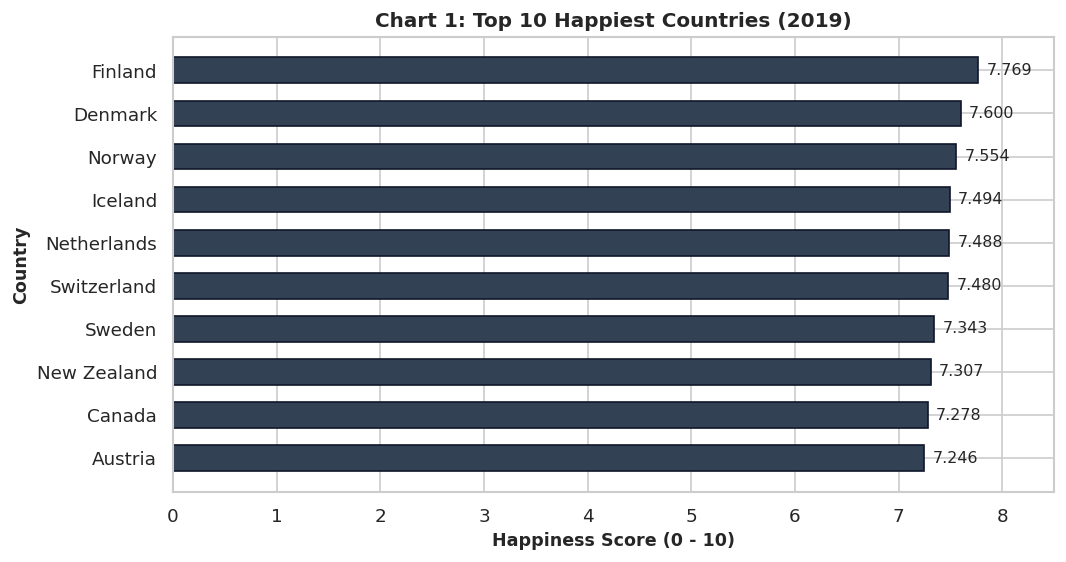

In [19]:
plt.figure(figsize=(9, 4.8))
top10_plot = df_2019.nsmallest(10, "rank").sort_values("score", ascending=True)
bars = plt.barh(top10_plot["country"], top10_plot["score"], color="#334155", edgecolor="#0f172a", height=0.6)
plt.xlim(0, 8.5)
plt.title("Chart 1: Top 10 Happiest Countries (2019)")
plt.xlabel("Happiness Score (0 - 10)")
plt.ylabel("Country")

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.08, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", ha="left", fontsize=9.5)
plt.show()


### Chart 2 (Line Chart): 5-Year regional score trends (2015 to 2019)

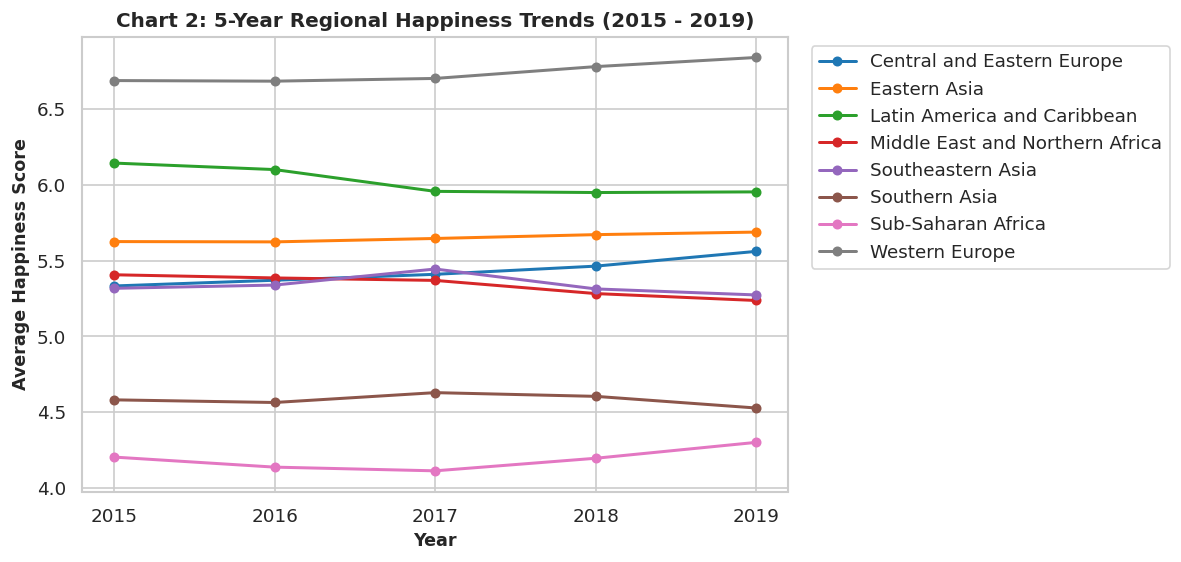

In [20]:
plt.figure(figsize=(10, 4.8))
reg_trends = all_years_df.groupby(["year", "region"])["score"].mean().unstack("region")
major_regions = [r for r in reg_trends.columns if r != "Other" and (df_2019["region"] == r).sum() >= 4]

colors = sns.color_palette("tab10", len(major_regions))
for i, reg in enumerate(major_regions):
    plt.plot(reg_trends.index, reg_trends[reg], marker="o", markersize=5, linewidth=1.8, label=reg, color=colors[i])

plt.xticks(range(2015, 2020))
plt.title("Chart 2: 5-Year Regional Happiness Trends (2015 - 2019)")
plt.xlabel("Year")
plt.ylabel("Average Happiness Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


### Chart 3 (Histogram): Global distribution of 2019 happiness scores

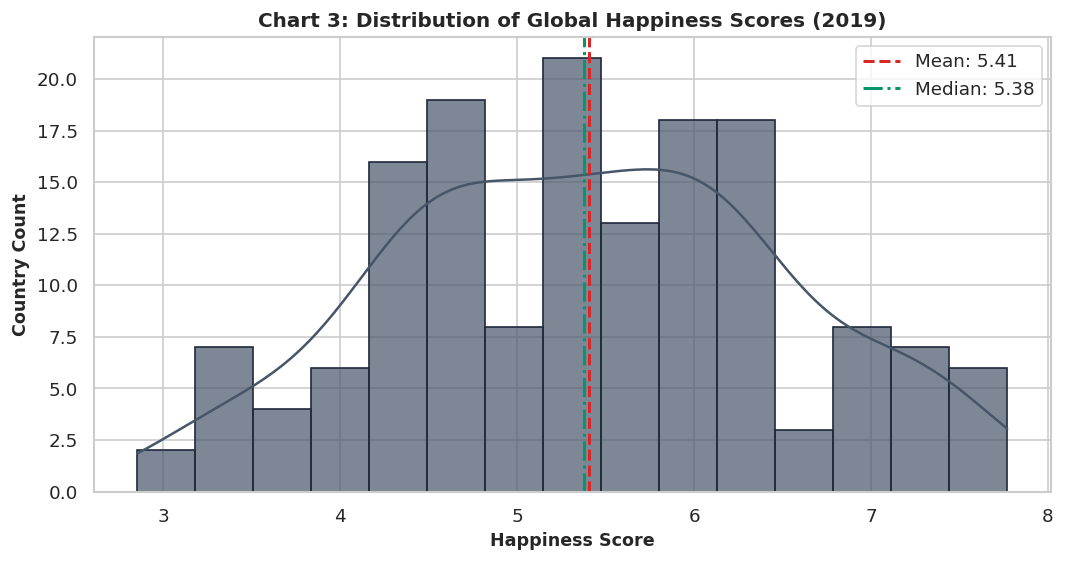

In [21]:
plt.figure(figsize=(9, 4.8))
sns.histplot(df_2019["score"], kde=True, bins=15, color="#475569", edgecolor="#1e293b", alpha=0.7)
mean_val = df_2019["score"].mean()
med_val = df_2019["score"].median()

plt.axvline(mean_val, color="#dc2626", linestyle="--", linewidth=1.8, label=f"Mean: {mean_val:.2f}")
plt.axvline(med_val, color="#059669", linestyle="-.", linewidth=1.8, label=f"Median: {med_val:.2f}")

plt.title("Chart 3: Distribution of Global Happiness Scores (2019)")
plt.xlabel("Happiness Score")
plt.ylabel("Country Count")
plt.legend()
plt.show()


### Chart 4 (Scatter Plot): GDP per capita vs Happiness Score

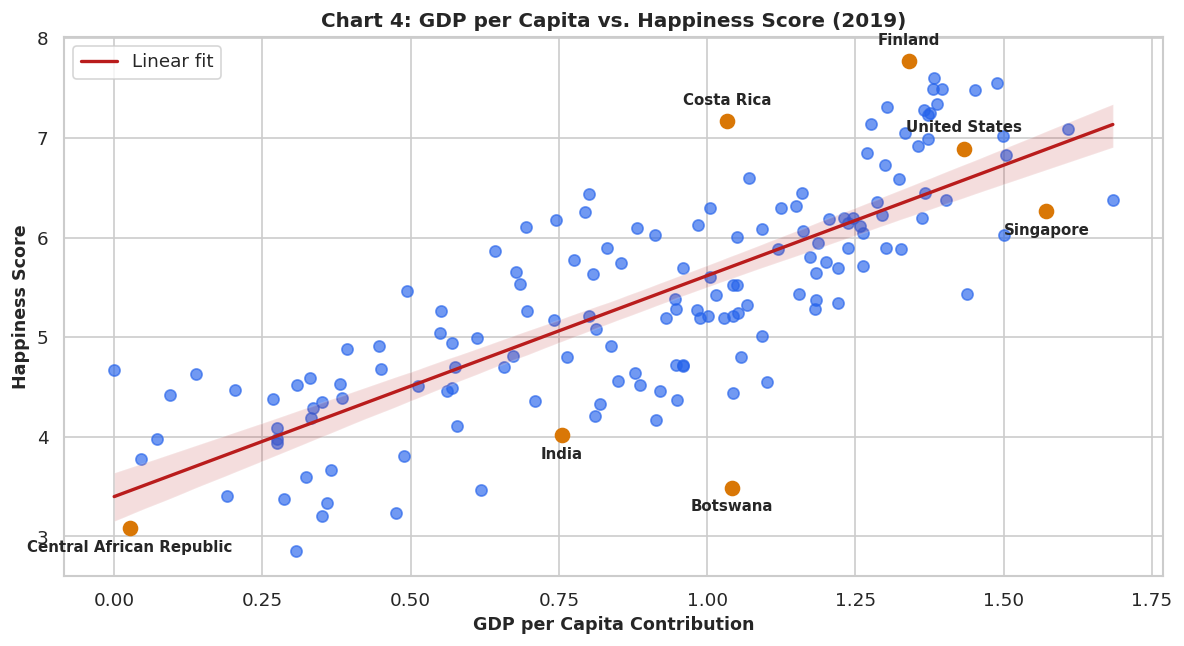

In [22]:
plt.figure(figsize=(10, 5.5))
sns.regplot(data=df_2019, x="gdp", y="score",
            scatter_kws={"alpha": 0.65, "color": "#2563eb", "s": 45},
            line_kws={"color": "#b91c1c", "linewidth": 2, "label": "Linear fit"})

annotated = ["Finland", "Costa Rica", "Singapore", "Botswana", "India", "United States", "Central African Republic"]
for country in annotated:
    match = df_2019[df_2019["country"] == country]
    if not match.empty:
        x_val = match["gdp"].values[0]
        y_val = match["score"].values[0]
        plt.scatter(x_val, y_val, color="#d97706", s=70, zorder=5)
        offset = 10 if country in ["Costa Rica", "Finland", "United States"] else -14
        plt.annotate(country, (x_val, y_val), textcoords="offset points", xytext=(0, offset),
                     ha="center", fontsize=9, fontweight="bold")

plt.title("Chart 4: GDP per Capita vs. Happiness Score (2019)")
plt.xlabel("GDP per Capita Contribution")
plt.ylabel("Happiness Score")
plt.legend(loc="upper left")
plt.show()


### Chart 5 (Donut Chart): Regional representation in 2019 dataset

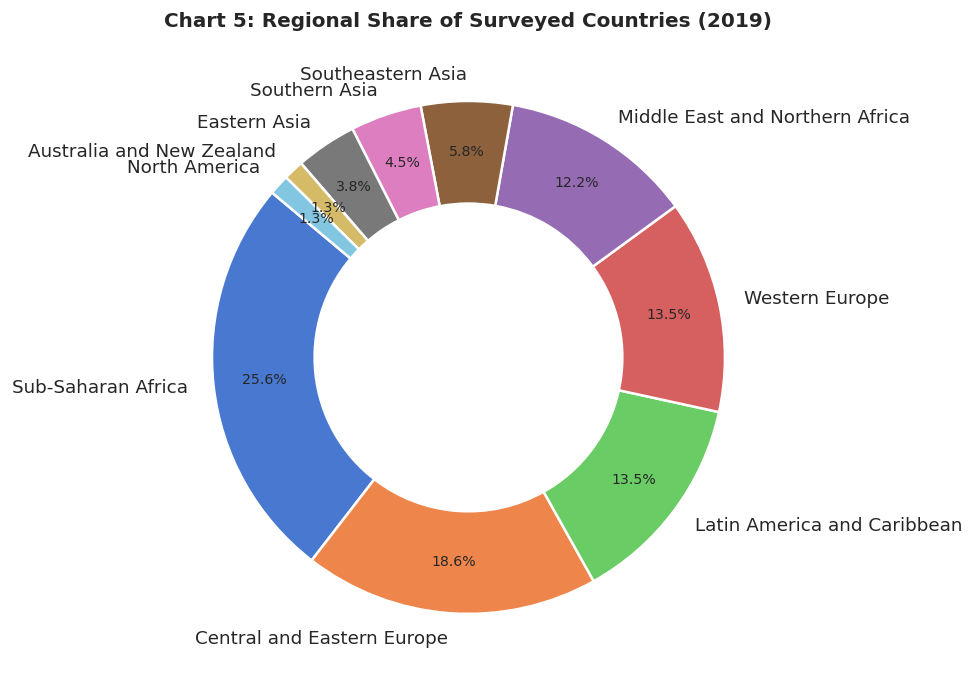

In [23]:
plt.figure(figsize=(7.5, 6.5))
reg_counts = df_2019["region"].value_counts()
colors = sns.color_palette("muted", len(reg_counts))
wedges, texts, autotexts = plt.pie(
    reg_counts, labels=reg_counts.index, autopct="%1.1f%%",
    startangle=140, colors=colors, pctdistance=0.8,
    wedgeprops=dict(width=0.4, edgecolor="white", linewidth=1.5)
)
for at in autotexts:
    at.set_fontsize(8.5)

plt.title("Chart 5: Regional Share of Surveyed Countries (2019)")
plt.show()


### Chart 6 (Heatmap): Correlation matrix of happiness drivers

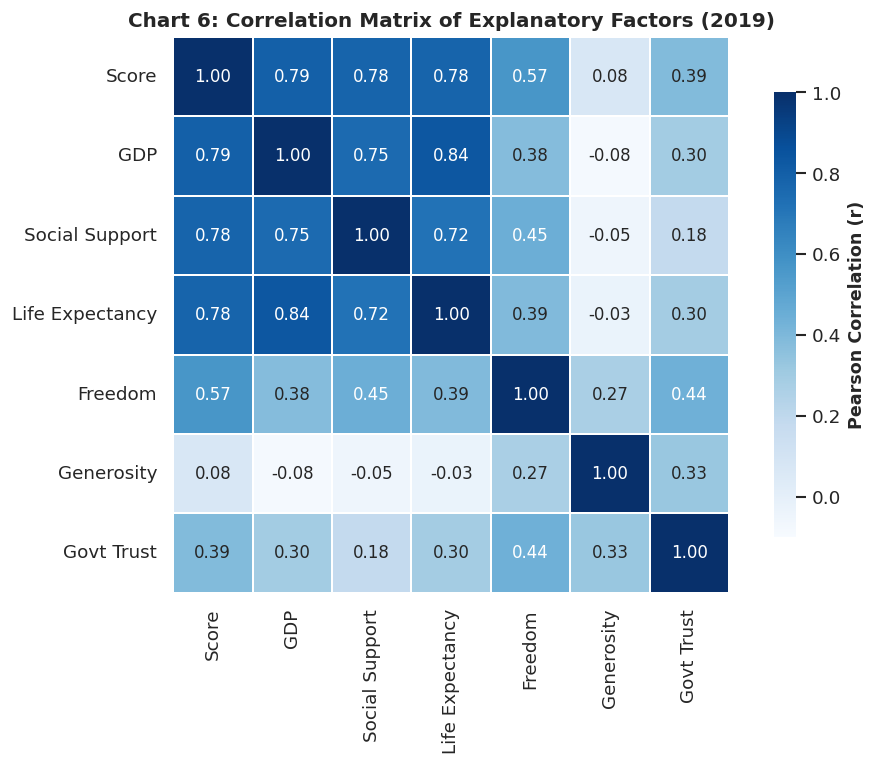

In [24]:
plt.figure(figsize=(8.5, 6.5))
corr_factors = ["score", "gdp", "social", "health", "freedom", "generosity", "corruption"]
corr_mat = df_2019[corr_factors].corr()
labels = {
    "score": "Score", "gdp": "GDP", "social": "Social Support",
    "health": "Life Expectancy", "freedom": "Freedom", "generosity": "Generosity", "corruption": "Govt Trust"
}
sns.heatmap(corr_mat.rename(index=labels, columns=labels), annot=True, fmt=".2f", cmap="Blues",
            vmin=-0.1, vmax=1.0, square=True, linewidths=1.0,
            cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"},
            annot_kws={"size": 10})
plt.title("Chart 6: Correlation Matrix of Explanatory Factors (2019)")
plt.show()


### Bonus Chart 7 (Box Plot): Regional happiness distribution and variance

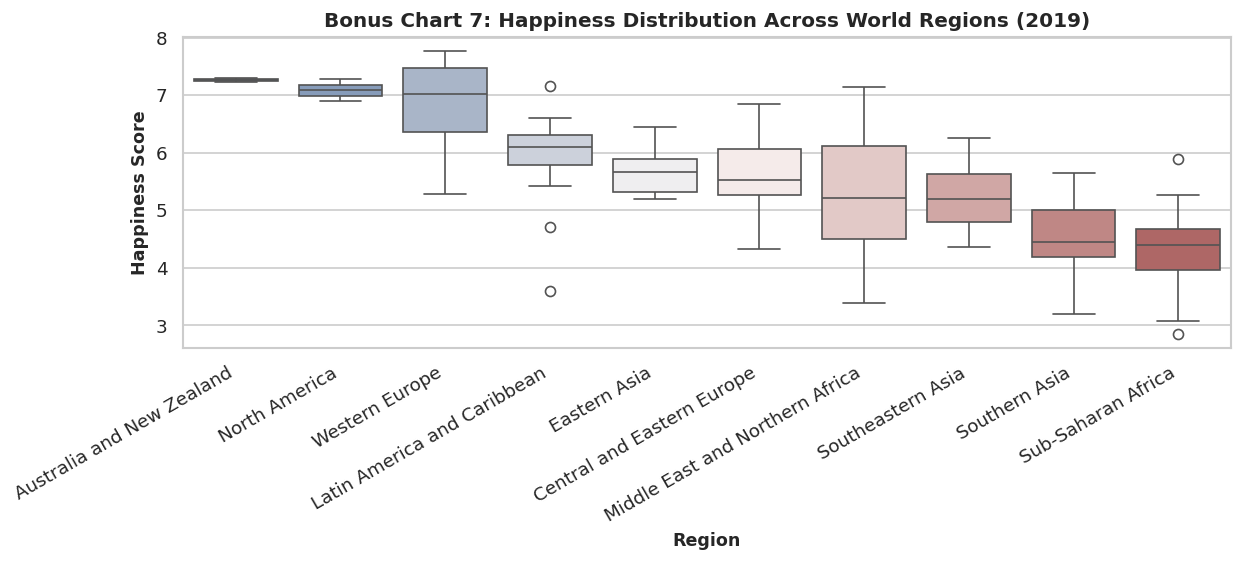

In [25]:
plt.figure(figsize=(10.5, 4.8))
order_reg = df_2019.groupby("region")["score"].median().sort_values(ascending=False).index
sns.boxplot(data=df_2019, x="region", y="score", order=order_reg, palette="vlag")
plt.title("Bonus Chart 7: Happiness Distribution Across World Regions (2019)")
plt.xlabel("Region")
plt.ylabel("Happiness Score")
plt.xticks(rotation=30, ha="right")
plt.show()


## Step 5: Insights report and recommendations

### 5 Data-backed insights:
1. **Economic output is strongly correlated with happiness, but has diminishing returns (Chart 4, Chart 6)**:
   GDP per capita exhibits the highest correlation with happiness ($r = 0.794$). However, above a certain wealth threshold, extra GDP does not translate linearly into higher happiness. For instance, Singapore and Qatar report among the highest GDP per capita scores in the world (~1.68), yet rank 34th and 29th respectively. Meanwhile, Costa Rica achieves rank 12 globally with a GDP score of 1.03, compensating through social ties and healthcare access.

2. **Social support is the strongest non-monetary pillar of well-being (Chart 6, Table Q1)**:
   Social support has the second highest correlation with national score ($r = 0.777$). Between the top 10 and bottom 5 countries, the average social support score drops by roughly 3.5x (from 1.53 down to 0.44). For policy decisions, investment in social safety nets, public parks, community care, and family support infrastructure yields direct measurable returns in population well-being.

3. **Regional disparities remain persistent over time (Chart 2, Chart 5)**:
   Western Europe and North America average around 6.9 to 7.1 in happiness, whereas Sub-Saharan Africa averages 4.31. Over the five observed years (2015 to 2019), regional trajectories remained steady with little churn across geographic tiers, underscoring that structural improvements require long-term institutional stability.

4. **Latin American nations punch consistently above their economic wealth (Table Q5, Chart 4)**:
   In the rank disparity analysis, Costa Rica (+43 spots), Mexico (+37 spots), and Guatemala (+47 spots) achieve happiness scores far higher than their GDP per capita rank would predict. By contrast, mineral-rich nations like Botswana (Rank 148 in happiness vs Rank 75 in GDP) exhibit large negative rank gaps, likely due to internal inequality and health challenges.

5. **Generosity shows negligible correlation with national happiness scores (Chart 6, Table Q2)**:
   Generosity had an $r = 0.076$ correlation with happiness. While individual charitable acts are positive, national life satisfaction is driven primarily by baseline economic security, public healthcare, personal freedom, and institutional trust rather than discretionary donations.

---

### Finding that surprised me the most:
The rank disparity analysis was the most surprising takeaway. Comparing GDP rank against happiness rank demonstrates that wealth alone is an incomplete proxy for national well-being. Middle-income nations with strong familial structures and accessible healthcare routinely outscore far wealthier peers who face higher social isolation or systemic inequality.
